## Cơ sở tham khảo từ Machine Learning Cơ Bản

- **Bài 11 — Feature Engineering:** đưa dữ liệu thô về feature vector có cùng kích thước.
- **Bài 12 — Binary Classifiers:** grayscale và vector hóa ảnh khuôn mặt.
- **Bài 13 — Softmax Regression:** Softmax, Cross-Entropy và cập nhật trọng số.
- **Bài 15 — Overfitting:** theo dõi Training Error và Validation Error để chọn mô hình phù hợp.

In [1]:
# ===== IMPORT LIBRARIES =====

import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from scipy import sparse

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

SEED = 42
#random.seed(SEED)
#np.random.seed(SEED)


## 1. Dataset path

Dataset đã được tải về có cấu trúc:

```text
Male and Female face dataset/
├── Female faces/
└── Male faces/
```

In [2]:
DATASET_DIR = Path("./Male and Female face dataset")

print("Dataset root:", DATASET_DIR.resolve())

assert DATASET_DIR.exists(), (
    f"Dataset path does not exist: {DATASET_DIR.resolve()}"
)

Dataset root: D:\NCKH\NCKH2_Nghiên cứu AI\softmax_gender_project\softmax_gender_project\Male and Female face dataset


## 2. Đọc ảnh và gán nhãn

Quy ước:
- `0` = Female
- `1` = Male

In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def infer_label_from_path(path: Path):
    parts = [p.lower().strip() for p in path.parts]

    if "female faces" in parts:
        return 0

    if "male faces" in parts:
        return 1

    return None


rows = []

for path in DATASET_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        label = infer_label_from_path(path)

        if label is not None:
            rows.append({
                "path": str(path),
                "label": label,
                "class_name": "Female" if label == 0 else "Male",
            })

df = pd.DataFrame(rows)

display(df.head())
display(df["class_name"].value_counts())

,path,label,class_name
0,Male and Female face dataset\Female Faces\0 (1...,0,Female
1,Male and Female face dataset\Female Faces\0 (1...,0,Female
2,Male and Female face dataset\Female Faces\0 (1...,0,Female
3,Male and Female face dataset\Female Faces\0 (1...,0,Female
4,Male and Female face dataset\Female Faces\0 (1...,0,Female


class_name
Male      1640
Female    1618
Name: count, dtype: int64

## 3. Kiểm tra dataset

- ảnh có đọc được hay không;
- kích thước ảnh ban đầu.

In [4]:
audit_rows = []
bad_paths = []

for idx, row in df.iterrows():
    path = Path(row["path"])

    try:
        with Image.open(path) as img:
            img = ImageOps.exif_transpose(img)
            width, height = img.size

        audit_rows.append({
            "index": idx,
            "width": width,
            "height": height,
        })

    except Exception as e:
        bad_paths.append((str(path), repr(e)))


audit = pd.DataFrame(audit_rows).set_index("index")
df = df.join(audit)

df = df.dropna(
    subset=["width", "height"]
).reset_index(drop=True)

print("Unreadable images:", len(bad_paths))

print("\nImage size summary:")
display(df[["width", "height"]].describe())
display(df["class_name"].value_counts())

Unreadable images: 0

Image size summary:


,width,height
count,3258.000000,3258.000000
mean,980.356354,1219.202578
std,860.382811,970.082866
min,194.000000,232.000000
25%,540.000000,733.000000
50%,736.000000,975.000000
75%,1024.000000,1300.000000
max,8675.000000,7680.000000


class_name
Male      1640
Female    1618
Name: count, dtype: int64

## 4. Kiểm tra dữ liệu

Quan sát một số ảnh để biết dataset có sự khác nhau về ánh sáng, góc mặt, tóc, background và cách crop hay không.

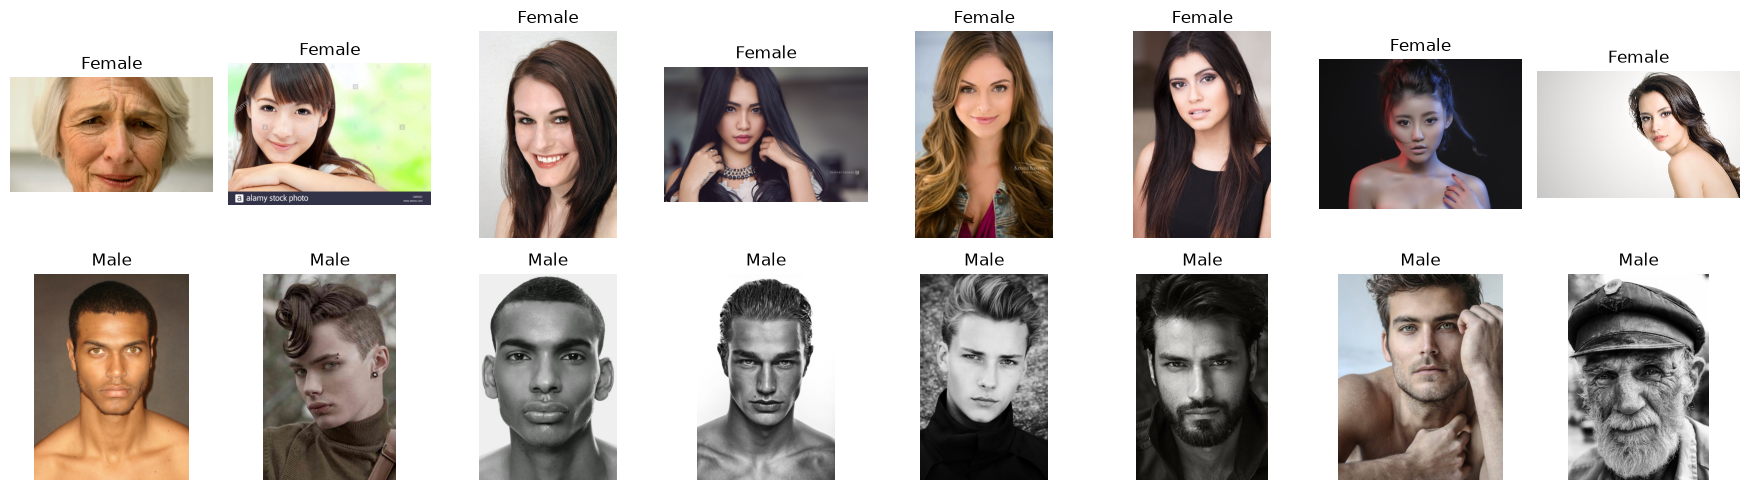

In [5]:
def show_random_samples(dataframe, n_per_class=8, seed=SEED):
    fig, axes = plt.subplots(
        2,
        n_per_class,
        figsize=(2.2 * n_per_class, 5)
    )

    for row_idx, (label, name) in enumerate([(0, "Female"), (1, "Male")]):
        subset = dataframe[dataframe["label"] == label]

        sample = subset.sample(
            n=min(n_per_class, len(subset)),
            random_state=None
        )

        for col_idx, (_, row) in enumerate(sample.iterrows()):
            ax = axes[row_idx, col_idx]

            img = Image.open(row["path"])
            img = ImageOps.exif_transpose(img).convert("RGB")

            ax.imshow(img)
            ax.axis("off")
            ax.set_title(name)

    plt.tight_layout()
    plt.show()


show_random_samples(df)

## 5. Chia Train / Validation / Test

- Train: 70%
- Validation: 15%
- Test: 15%

In [6]:
df_train, df_temp = train_test_split(
    df,
    test_size=0.30,
    random_state=None,
    stratify=df["label"],
)

df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    random_state=None,
    stratify=df_temp["label"],
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)


def print_split(name, frame):
    print(
        f"{name:10s} n={len(frame):4d} | "
        f"{frame['class_name'].value_counts().to_dict()}"
    )


print_split("Train", df_train)
print_split("Validation", df_val)
print_split("Test", df_test)

Train      n=2280 | {'Male': 1148, 'Female': 1132}
Validation n= 489 | {'Male': 246, 'Female': 243}
Test       n= 489 | {'Male': 246, 'Female': 243}


## 6. Feature Extraction
Các bước tiền xử lý:

1. chuyển sang grayscale;
2. resize tất cả về 64x64
3. chia pixel cho 255 để đưa về [0,1];
4. trải ảnh thành vector.

In [7]:
IMAGE_SIZE = (64, 64)  # width, height


def preprocess_image(path, image_size=IMAGE_SIZE):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img)
        img = img.convert("L")
        img = img.resize(
            image_size,
            Image.Resampling.LANCZOS
        )

        x = np.asarray(
            img,
            dtype=np.float64
        ) / 255.0

    return x


def dataframe_to_matrix(frame):
    images = np.stack(
        [preprocess_image(p) for p in frame["path"]],
        axis=0
    )

    # Mỗi ảnh ban đầu là một hàng: (N, 4096)
    X_row = images.reshape(len(images), -1)

    # mỗi sample là một cột: (4096, N)
    X = X_row.T

    # Thêm hàng toàn số 1 để gộp bias vào W: (4097, N)
    X = np.vstack((
        np.ones((1, X.shape[1]), dtype=np.float64),
        X
    ))

    y = frame["label"].to_numpy(dtype=np.int64)

    return X, y


X_train, y_train = dataframe_to_matrix(df_train)
X_val, y_val = dataframe_to_matrix(df_val)
X_test, y_test = dataframe_to_matrix(df_test)

print("Train matrix (d+1, N):", X_train.shape)
print("Validation matrix (d+1, N):", X_val.shape)
print("Test matrix (d+1, N):", X_test.shape)
print("Image features:", X_train.shape[0] - 1)


d:\SOFTWARE\Python\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Train matrix (d+1, N): (4097, 2280)
Validation matrix (d+1, N): (4097, 489)
Test matrix (d+1, N): (4097, 489)
Image features: 4096


## 7. Softmax Regression

- mỗi **cột** của X là một sample;
- bias được gộp vào W bằng hàng số 1 trong X;
- dùng hàm `softmax_stable(Z)` với `axis=0`;
- label được đổi sang one-hot bằng `convert_labels`;
- loss dùng Cross-Entropy;
- training dùng SGD với công thức cập nhật:
Điểm khác so với code demo của Bài 13: project không lưu toàn bộ ma trận W sau từng sample vì ảnh có 4097 features và số lần cập nhật rất lớn. Thay vào đó chỉ giữ W hiện tại và W tại epoch có Validation Loss nhỏ nhất.

In [8]:
# Số class của project
C = 2

def softmax_stable(Z):
    """
    Compute softmax values for each set of scores in Z.
    Giống Bài 13: mỗi cột của Z là một set of scores.
    """
    e_Z = np.exp(
        Z - np.max(Z, axis=0, keepdims=True)
    )
    A = e_Z / e_Z.sum(axis=0)
    return A


# One-hot coding
def convert_labels(y, C=C):
    """
    Convert label vector y thành ma trận one-hot Y có shape (C, N).
    Mỗi cột tương ứng với một sample.
    """
    Y = sparse.coo_matrix(
        (
            np.ones_like(y),
            (y, np.arange(len(y)))
        ),
        shape=(C, len(y))
    ).toarray()

    return Y


def cost(X, Y, W):
    A = softmax_stable(W.T.dot(X))

    return -np.sum(
        Y * np.log(A + 1e-12)
    ) / X.shape[1]


def grad(X, Y, W):
    A = softmax_stable(W.T.dot(X))
    E = A - Y

    return X.dot(E.T) / X.shape[1]


def softmax_regression(
    X_train,
    y_train,
    X_val,
    y_val,
    W_init,
    eta=0.001,
    max_epoch=200,
    random_state=None,
    verbose_every=20,
):
    """
    Train Softmax Regression bằng SGD.

    Phần update từng sample giữ cùng dạng với Bài 13:
        W = W + eta * xi.dot((yi - ai).T)

    Bổ sung cho project:
    - tính Train/Validation Cross-Entropy sau mỗi epoch;
    - lưu W tại Validation Loss nhỏ nhất (theo tinh thần Bài 15).
    """
    rng = np.random.default_rng(random_state)

    W = W_init.copy()

    C = W.shape[1]
    Y_train = convert_labels(y_train, C)
    Y_val = convert_labels(y_val, C)

    N = X_train.shape[1]
    d = X_train.shape[0]

    history = {
        "train_loss": [],
        "val_loss": [],
    }

    best_val_loss = np.inf
    best_epoch = -1
    best_W = W.copy()

    for epoch in range(max_epoch):
        # mix data 
        mix_id = rng.permutation(N)

        for i in mix_id:
            xi = X_train[:, i].reshape(d, 1)
            yi = Y_train[:, i].reshape(C, 1)

            ai = softmax_stable(
                W.T.dot(xi)
            )

            # Công thức update SGD 
            W = W + eta * xi.dot(
                (yi - ai).T
            )

        train_loss = cost(
            X_train,
            Y_train,
            W
        )

        val_loss = cost(
            X_val,
            Y_val,
            W
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_W = W.copy()

        if (
            epoch == 0
            or (epoch + 1) % verbose_every == 0
        ):
            print(
                f"Epoch {epoch+1:4d} | "
                f"train loss={train_loss:.4f} | "
                f"val loss={val_loss:.4f}"
            )

    return best_W, history, best_epoch, best_val_loss


def pred(W, X):
    """
    Predict class của mỗi cột trong X.
    Giống hàm pred() trong Bài 13.
    """
    A = softmax_stable(
        W.T.dot(X)
    )

    return np.argmax(A, axis=0)


## 8. Train Softmax

khởi tạo ma trận trọng số \(W\) rồi truyền vào hàm `softmax_regression`.
dùng random initialization nhưng nhân hệ số nhỏ `0.001` để logits ban đầu không quá lớn.

In [9]:
eta = 0.001
max_epoch = 200

d = X_train.shape[0]

# Random initialization giống Bài 13,
# nhưng scale nhỏ vì dữ liệu ảnh có số chiều lớn.
W_init = 0.01 * np.random.randn(d, C)

W_best, history, best_epoch, best_val_loss = softmax_regression(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    W_init=W_init,
    eta=eta,
    max_epoch=max_epoch,
    random_state=None,
    verbose_every=20,
)

print("\nBest epoch:", best_epoch + 1)
print("Best validation loss:", best_val_loss)


Epoch    1 | train loss=0.5654 | val loss=0.5771
Epoch   20 | train loss=0.3243 | val loss=0.4585
Epoch   40 | train loss=0.3805 | val loss=0.5706
Epoch   60 | train loss=0.2508 | val loss=0.4514
Epoch   80 | train loss=0.3363 | val loss=0.5766
Epoch  100 | train loss=0.1826 | val loss=0.4222
Epoch  120 | train loss=0.1369 | val loss=0.3746
Epoch  140 | train loss=0.1818 | val loss=0.4075
Epoch  160 | train loss=0.1116 | val loss=0.3546
Epoch  180 | train loss=0.1066 | val loss=0.3512
Epoch  200 | train loss=0.1008 | val loss=0.3498

Best epoch: 192
Best validation loss: 0.3411762499462056


## 9. Training Error và Validation Error

Cross-Entropy được tính sau mỗi epoch.

- Training Loss và Validation Loss cùng cao → underfitting;
- cả hai thấp và gần nhau → fit tương đối tốt;
- Training Loss tiếp tục giảm nhưng Validation Loss tăng → overfitting.

Đường thẳng đứng đánh dấu epoch có Validation Loss nhỏ nhất.

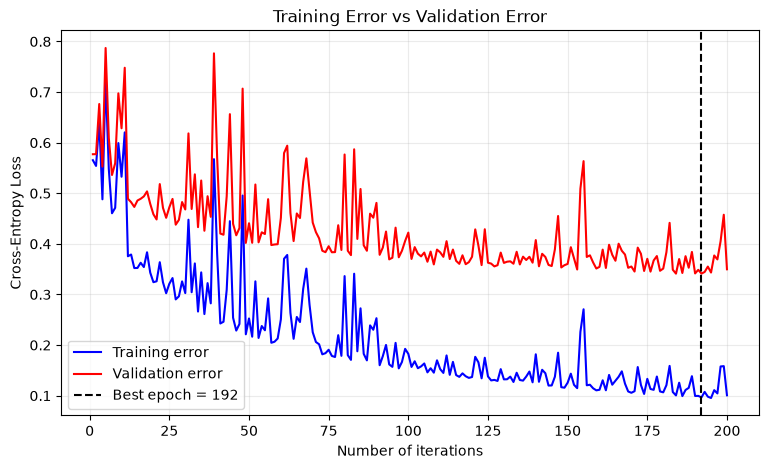

In [10]:
epoch_axis = np.arange(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    epoch_axis,
    history["train_loss"],
    color="blue",
    label="Training error"
)

plt.plot(
    epoch_axis,
    history["val_loss"],
    color="red",
    label="Validation error"
)

plt.axvline(
    best_epoch + 1,
    linestyle="--",
    color="black",
    label=f"Best epoch = {best_epoch + 1}"
)

plt.xlabel("Number of iterations")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Error vs Validation Error")

plt.legend()
plt.grid(alpha=0.25)
plt.show()


## 10. Final Test Accuracy

Sau khi train mô hình trên tệp Validation thì mới đánh giá trên Test set.

In [11]:
y_test_pred = pred(
    W_best,
    X_test
)

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)* 100

print(
    print(f"Test accuracy: {test_accuracy:.2f}%")
)


Test accuracy: 88.55%
None
